# Actividades guiadas de regresión

Cada sección incluye ejemplos y espacios para que desarrolles tu propio código, con recomendaciones y comentarios para facilitar el aprendizaje.

## 1. Ejercicio: Regresión lineal simple

En este ejercicio aprenderás a ajustar un modelo de regresión lineal simple para predecir una variable a partir de otra. Usaremos un dataset de ejemplo y te dejaremos un espacio para que modifiques el código y experimentes.

**Ejemplo:** Predicción de precio de casas según el área construida.

In [208]:
# Ejemplo: Regresión lineal simple con Boston Housing
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cargar datos Boston Housing
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/housing/housing.data"
columnas = ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE","DIS","RAD","TAX","PTRATIO","B","LSTAT","MEDV"]
df = pd.read_csv(url, delim_whitespace=True, names=columnas)
print(df.info())
print (df.head())

# Usar una sola variable (RM: número de habitaciones)
X = df[['RM']]
y = df['MEDV']

modelo = LinearRegression()
modelo.fit(X, y)

print('Coeficiente:', modelo.coef_[0])
print('Intercepto:', modelo.intercept_)

# Función auxiliar para evaluar y mostrar métricas
def evaluar_modelo(y_true, y_pred, nombre):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"Modelo: {nombre}\nMAE={mae:.3f} | MSE={mse:.3f} | R2={r2:.3f}\n")
    return {"MAE": mae, "MSE": mse, "R2": r2}

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB
None
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2  0.02729 

/tmp/ipython-input-996469191.py:10: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True, names=columnas)


**Fuente de datos:** UCI ML & Kaggle Repository → https://www.kaggle.com/code/prasadperera/the-boston-housing-dataset

The Boston Housing Dataset is a derived from information collected by the U.S. Census Service concerning housing in the area of Boston MA. The following describes the dataset columns:

- CRIM - per capita crime rate by town
- ZN - proportion of residential land zoned for lots over 25,000 sq.ft.
- INDUS - proportion of non-retail business acres per town.
- CHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)
- NOX - nitric oxides concentration (parts per 10 million)
- RM - average number of rooms per dwelling
- AGE - proportion of owner-occupied units built prior to 1940
- DIS - weighted distances to five Boston employment centres
- RAD - index of accessibility to radial highways
- TAX - full-value property-tax rate per \$10,000
- PTRATIO - pupil-teacher ratio by town
- B - 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
- LSTAT - % lower status of the population
- MEDV - Median value of owner-occupied homes in \$1000's

Ahora es tu turno...

1. Realiza un mapa de calor que muestre la correlación entre las diferentes variables del dataset.
2. Cambia la variable independiente (por ejemplo, usa 'LSTAT' o 'AGE' en vez de 'RM'). En especial según el análisis de correlación realizado en el punto anterior.
3. Ajusta el modelo y observa cómo cambian el coeficiente y el intercepto.
4. Grafica la relación entre la variable elegida y el precio (MEDV).
5. Escribe una breve conclusión sobre el impacto de la variable en el precio de la vivienda.

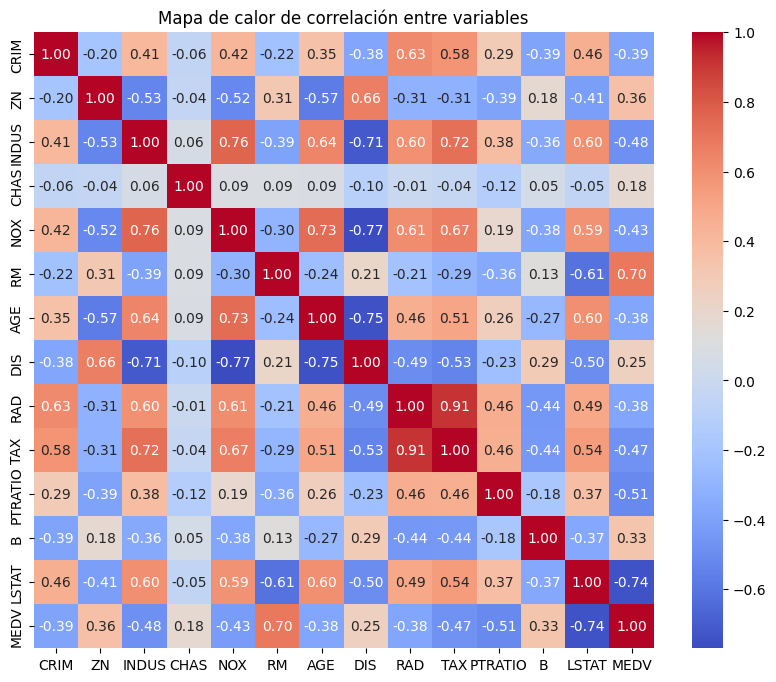

In [209]:
# Actividad: Regresión lineal simple con Boston Housing
'''
1. Realiza un mapa de calor que muestre la correlación entre las diferentes variables del dataset.
2. Cambia la variable independiente (por ejemplo, usa 'LSTAT' o 'AGE' en vez de 'RM'). En especial según el análisis de correlación realizado en el punto anterior.
3. Ajusta el modelo y observa cómo cambian el coeficiente y el intercepto.
4. Grafica la relación entre la variable elegida y el precio (MEDV).
5. Escribe una breve conclusión sobre el impacto de la variable en el precio de la vivienda.
'''
# 1.1 Mapa de calor
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de calor de correlación entre variables')
plt.show()


Se observa que para la variable MEDV, es decir el valor promedio de la vivienda, hay variables con una correlación "fuerte", digamos menor a -0.50 y mayor a 0.50:
* RM (Numero de cuartos promedio) - Corr = 0.70
* LSTAT (% de estatus socioeconómico más bajo de la población) - Corr = -0.74
* PTRATIO (Razón de estudiantes a maestros por pueblo) - Corr = -0.51

Calculamos entonces modelos de regresión lineal respecto a cada variable.

In [210]:
# ==============================================================================
# 1.2 Calculo de modelos de regresión lineal respecto a diferenes variables
# independientes
# ==============================================================================
variables = {
    'modelo con RM': ['RM'],
    'modelo con LSTAT': ['LSTAT'],
    'modelo con PTRATIO': ['PTRATIO']
}

# ==============================================================================
# 1.3 Se vuelve a calcular el modelo para las nuevas variables independienes
# y se usa nuevamente la variable RM para mayor consistencia en el código
# ==============================================================================
def calcular_modelo(nombre, variable):
    X = df[[variable]]
    y = df['MEDV']
    x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    modelo = LinearRegression()
    modelo.fit(x_train, y_train)
    y_pred = modelo.predict(x_test)
    print("Coeficientes de ",nombre,"\n")
    print('Coeficiente:', modelo.coef_[0],)
    print('Intercepto:', modelo.intercept_)
    evaluar_modelo(y_test, y_pred, nombre)
    print("-----------------------------------------------------------------")
    return modelo

for nombre, variable in variables.items():
    calcular_modelo(nombre, variable[0])


Coeficientes de  modelo con RM 

Coeficiente: 9.348301406497727
Intercepto: -36.24631889813795
Modelo: modelo con RM
MAE=4.478 | MSE=46.145 | R2=0.371

-----------------------------------------------------------------
Coeficientes de  modelo con LSTAT 

Coeficiente: -0.966530901950353
Intercepto: 34.83694982031851
Modelo: modelo con LSTAT
MAE=4.185 | MSE=33.520 | R2=0.543

-----------------------------------------------------------------
Coeficientes de  modelo con PTRATIO 

Coeficiente: -2.056823160036797
Intercepto: 60.47407296576316
Modelo: modelo con PTRATIO
MAE=5.212 | MSE=49.976 | R2=0.319

-----------------------------------------------------------------


* Como era de esperarse, el signo del coeficiente está ligado al signo de la correlación mostrada en el mapa de calor.
* Del cálculo de las métricas de función de pérdida, podemos ver que el mejor modelo parece ser el que se hace con LSTAT, pues tiene un menor valor para las funciones MAE y MSE, y un mayor valor para el coeficiente de determinación R2

Coeficientes de  modelo con RM 

Coeficiente: 9.348301406497727
Intercepto: -36.24631889813795
Modelo: modelo con RM
MAE=4.478 | MSE=46.145 | R2=0.371

-----------------------------------------------------------------


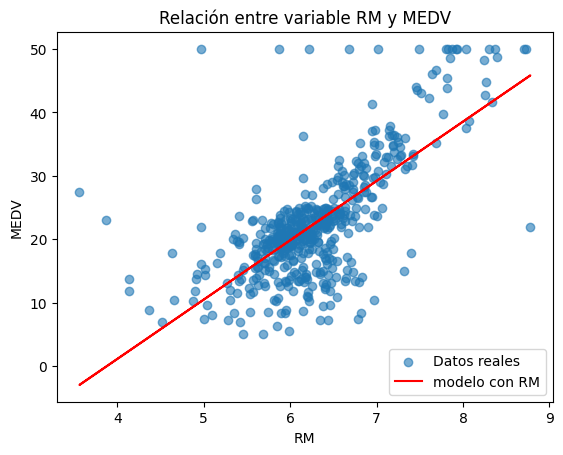

Coeficientes de  modelo con LSTAT 

Coeficiente: -0.966530901950353
Intercepto: 34.83694982031851
Modelo: modelo con LSTAT
MAE=4.185 | MSE=33.520 | R2=0.543

-----------------------------------------------------------------


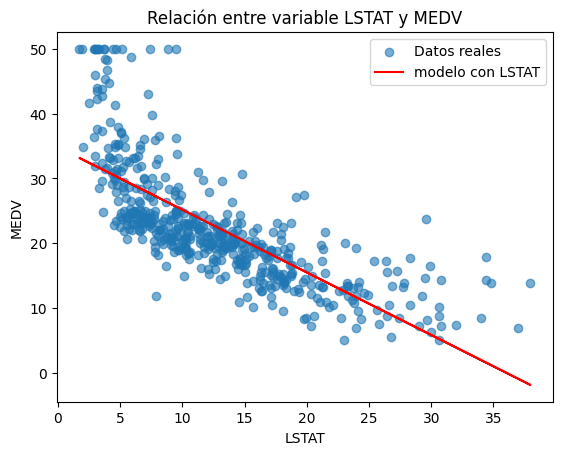

Coeficientes de  modelo con PTRATIO 

Coeficiente: -2.056823160036797
Intercepto: 60.47407296576316
Modelo: modelo con PTRATIO
MAE=5.212 | MSE=49.976 | R2=0.319

-----------------------------------------------------------------


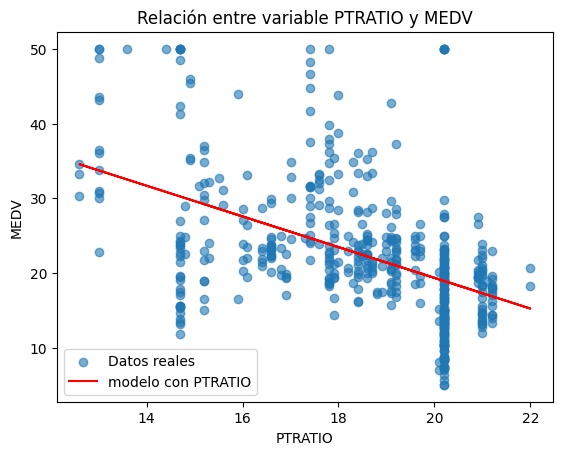

In [211]:
# ==============================================================================
# 1.4 Se grafican las relaciones entre las variables independientes y la
# variable dependiente. En rojo, se grafica la recta predicha por el modelo
# ==============================================================================
for nombre, variable in variables.items():
    #plt.figure(figsize=(10, 8))

    X = df[[variable[0]]]
    y = df['MEDV']
    y_line = calcular_modelo(nombre,variable[0]).predict(X)
    plt.scatter(X, y, label='Datos reales', alpha=0.6)
    plt.plot(df[variable[0]], y_line,c='r', label=nombre)
    plt.xlabel(variable[0])
    plt.ylabel('MEDV')
    plt.title(f'Relación entre variable {variable[0]} y MEDV')
    plt.legend()
    plt.show()

# ==============================================================================
# 1.5 De acuerdo a los modelos de regresión lineal calculados, se puede ver que:

# - Dependiendo de la variable elegida, así mismo variará el precio de la
#   vivienda: si escogemos el número de cuartos promedio (RM), vemos que a medida
#   que aumenta el número de cuartos, aumentará el precio, mientras que para las
#   variables de % de estatus socioeconómico (LSTAT) y razón de estudiantes a
#   maestros, a medida que aumentan sus valores, el precio será menor.

# - La variable que pareciera predecir mejor el precio es LSTAT, esto puede verse
#   reflejado en que tiene una menor dispersión de sus datos comparada con las
#   otras dos variables

## 2. Ejercicio: Regresión lineal múltiple

En este ejercicio aprenderás a ajustar un modelo de regresión lineal múltiple para predecir una variable a partir de varias características. Usaremos un dataset de ejemplo y te dejaremos un espacio para que modifiques el código y experimentes.

**Ejemplo:** Predicción de consumo energético según temperatura y humedad.

In [212]:
# Ejemplo: Regresión lineal múltiple con Boston Housing
# from sklearn.datasets import load_boston
import pandas as pd
from sklearn.linear_model import LinearRegression

# Cargar datos Boston Housing
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/housing/housing.data"
columnas = ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE","DIS","RAD","TAX","PTRATIO","B","LSTAT","MEDV"]
df = pd.read_csv(url, delim_whitespace=True, names=columnas)
df.head()

# Usar varias variables predictoras
X = df[['RM', 'LSTAT', 'PTRATIO']]
y = df['MEDV']

modelo = LinearRegression()
modelo.fit(X, y)

print('Coeficientes:', modelo.coef_)
print('Intercepto:', modelo.intercept_)

Coeficientes: [ 4.51542094 -0.57180569 -0.93072256]
Intercepto: 18.567111505395246


/tmp/ipython-input-2515044430.py:9: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True, names=columnas)


Ahora es tu turno...

1. Cambia las variables que alimentan el modelo de regresión y observa cómo cambian los resultados.
2. Compara el desempeño respecto a otros modelos de regresión como la regresión de Ridge o Lasso. Aqui es importante que revise los parámetros de regularización y cómo afectan el ajuste del modelo.
3. Realiza una tabla comparativa de las métricas de desempeño de los modelos utilizados con el mejor resultado obtenido incluyendo una columna donde mencione las características utilizadas.
4. Elabora gráficas de salida que permitan comparar el desempeño de los diferentes modelos (muestra solo el mejor resultado).
5. Realiza una breve conclusión como análisis del impacto de las variables en el precio de la vivienda.


In [213]:
from sklearn.linear_model import Ridge, Lasso

# Actividad: Regresión lineal múltiple con Boston Housing
'''
1. Cambia las variables que alimentan el modelo de regresión y observa cómo cambian los resultados.
2. Compara el desempeño respecto a otros modelos de regresión como la regresión de Ridge o Lasso. Aqui es importante que revise los parámetros de regularización y cómo afectan el ajuste del modelo.
3. Realiza una tabla comparativa de las métricas de desempeño de los modelos utilizados con el mejor resultado obtenido incluyendo una columna donde mencione las características utilizadas.
4. Elabora gráficas de salida que permitan comparar el desempeño de los diferentes modelos (muestra solo el mejor resultado).
5. Realiza una breve conclusión como análisis del impacto de las variables en el precio de la vivienda.
'''
# ==============================================================================
# 2.1 Se escogen las variables AGE, NOX y TAX las cuales tienen una correlacion
# que le sigue en magnitud a las variables de ejemplo.
# ==============================================================================
X = df[['AGE', 'NOX', 'TAX']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape
# ==============================================================================
# 2.2 Se compara el desempeño respecto a otros modelos de regresión.
# ==============================================================================

# Se definen los modelos
modelos = {
    "Lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000)
}

metricas = {}
for nombre, modelo in modelos.items():
    if nombre == "Ridge":
      alphas = [1.0, 2.0,10.0,100.0,1000.0,10000.0] # Se escogen diferentes alpha para el modelo Ridge
    elif nombre == "Lasso":
      alphas = [0.1, 0.3, 0.5, 0.8, 1.0] # Se escogen diferentes alpha para el modelo Lasso
    else:
      alphas =[0]

    for alpha in alphas:
      if nombre == "Ridge" or nombre == "Lasso":
        modelo.set_params(alpha=alpha) # Para los modelos Ridge y Lasso, se actualiza el parámetro alpha

      modelo.fit(X_train, y_train)
      y_pred = modelo.predict(X_test)
      metricas[nombre+"_"+str(alpha)] = evaluar_modelo(y_test, y_pred, nombre+"_"+str(alpha))



Modelo: Lineal_0
MAE=5.202 | MSE=52.369 | R2=0.286

Modelo: Ridge_1.0
MAE=5.168 | MSE=52.028 | R2=0.291

Modelo: Ridge_2.0
MAE=5.160 | MSE=51.896 | R2=0.292

Modelo: Ridge_10.0
MAE=5.145 | MSE=51.708 | R2=0.295

Modelo: Ridge_100.0
MAE=5.138 | MSE=51.658 | R2=0.296

Modelo: Ridge_1000.0
MAE=5.138 | MSE=51.662 | R2=0.296

Modelo: Ridge_10000.0
MAE=5.142 | MSE=51.747 | R2=0.294

Modelo: Lasso_0.1
MAE=5.137 | MSE=51.658 | R2=0.296

Modelo: Lasso_0.3
MAE=5.138 | MSE=51.672 | R2=0.295

Modelo: Lasso_0.5
MAE=5.139 | MSE=51.686 | R2=0.295

Modelo: Lasso_0.8
MAE=5.140 | MSE=51.706 | R2=0.295

Modelo: Lasso_1.0
MAE=5.141 | MSE=51.720 | R2=0.295



In [214]:
# ==============================================================================
# 2.3 Se realiza una tabla comparativa con las métricas, usando las mejores regresiones
# de cada modelo
# ==============================================================================

import pandas as pd
print(metricas)
df_metricas = pd.DataFrame(metricas)
df_metricas.transpose()
df_metricas= df_metricas[["Lineal_0","Ridge_100.0","Lasso_0.1"]]
df_metricas.rename(columns={"Lineal_0":"Lineal","Ridge_100.0":"Ridge","Lasso_0.1":"Lasso"},inplace=True)
df_metricas.loc['alpha'] = ['na','100.0','0.1']
df_metricas.head()

{'Lineal_0': {'MAE': 5.202307678154858, 'MSE': 52.36919358409932, 'R2': 0.28587901336537713}, 'Ridge_1.0': {'MAE': 5.168445410087513, 'MSE': 52.028095842168256, 'R2': 0.29053031767877047}, 'Ridge_2.0': {'MAE': 5.1599750136339555, 'MSE': 51.89584575199412, 'R2': 0.29233371693726784}, 'Ridge_10.0': {'MAE': 5.144606915306925, 'MSE': 51.70757730081345, 'R2': 0.2949009982511076}, 'Ridge_100.0': {'MAE': 5.137887142348329, 'MSE': 51.65751511142218, 'R2': 0.2955836602826276}, 'Ridge_1000.0': {'MAE': 5.137591154206405, 'MSE': 51.66151239252615, 'R2': 0.2955291522382897}, 'Ridge_10000.0': {'MAE': 5.142442316698564, 'MSE': 51.74721858591199, 'R2': 0.29436043858828653}, 'Lasso_0.1': {'MAE': 5.137315839056345, 'MSE': 51.65807444258867, 'R2': 0.2955760330862335}, 'Lasso_0.3': {'MAE': 5.13808578476957, 'MSE': 51.67172064465516, 'R2': 0.2953899496540361}, 'Lasso_0.5': {'MAE': 5.138858718695647, 'MSE': 51.68552074038388, 'R2': 0.2952017676847717}, 'Lasso_0.8': {'MAE': 5.140018119584763, 'MSE': 51.70641

,Lineal,Ridge,Lasso
MAE,5.202308,5.137887,5.137316
MSE,52.369194,51.657515,51.658074
R2,0.285879,0.295584,0.295576
alpha,na,100.0,0.1


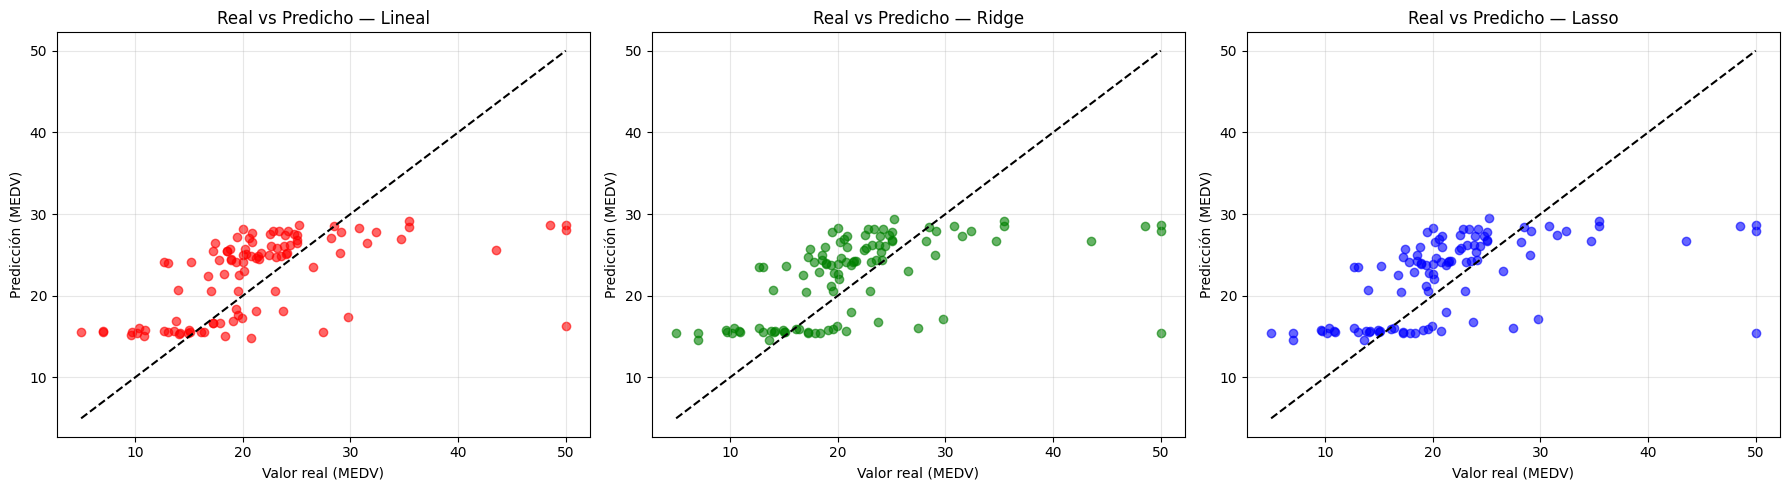

In [215]:
# ==============================================================================
# 2.4 Se elabora una gráfica comparativa usando los mejores modelos
# ==============================================================================

modelos = {
    "Lineal": LinearRegression(),
    "Ridge": Ridge(alpha=100),
    "Lasso": Lasso(alpha=0.1, max_iter=10000)
}

colors = ['r', 'g', 'b']
model_names = list(modelos.keys())
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for i, nombre in enumerate(model_names):
    modelo = modelos[nombre]
    modelo.fit(X_train, y_train) # Fit the model before predicting
    y_pred = modelo.predict(X_test)
    axs[i].scatter(y_test, y_pred, alpha=0.6, color=colors[i])
    axs[i].set_xlabel("Valor real (MEDV)")
    axs[i].set_ylabel("Predicción (MEDV)")
    axs[i].set_title(f"Real vs Predicho — {nombre}")
    minv, maxv = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    axs[i].plot([minv, maxv], [minv, maxv], 'k--')
    axs[i].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

2.5 En esta caso se puede observar que las variables escogidas (AGE, NOX y TAX) no generan una buena predición del valor de la vivienda. Mientras que el valor real aumenta, el valor predicho tiene un limite. Esto se ve en la gran dispersión que existe a ambos lados respecto de la recta.

## 3. Ejercicio: Regresión para imputación de datos

En este ejercicio aprenderás a usar regresión para rellenar valores faltantes en un dataset. Usaremos un ejemplo y te dejaremos un espacio para que selecciones las variables y completes el proceso de imputación.

**Ejemplo:** Imputación de valores faltantes en consumo energético usando temperatura y humedad.

In [216]:
# Ejemplo: Imputación de datos faltantes con regresión usando datos de energía
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Cargar datos de Appliances Energy (fragmento)
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00374/energydata_complete.csv'
df_original = pd.read_csv(url)
df_original.info()
df_original['date']=pd.to_datetime(df_original['date'])
df_original.head()

# Seleccionar variables relevantes y simular valores faltantes
df = df_original[['T_out', 'RH_out', 'Appliances']].copy()
df.loc[10:20, 'Appliances'] = None

# Separar filas con y sin datos faltantes
df_train = df.dropna()
df_missing = df[df['Appliances'].isna()]

# Entrenar modelo para imputar consumo
X_train = df_train[['T_out', 'RH_out']]
y_train = df_train['Appliances']
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Imputar valores faltantes
X_missing = df_missing[['T_out', 'RH_out']]
df.loc[df['Appliances'].isna(), 'Appliances'] = modelo.predict(X_missing)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

Ahora es tu turno...

1. Revisa el dataset energy data (desde la línea donde se carga la base de datos) y genera un mapa de calor utilizando la correlación entre las características con respecto a la variable objetivo (por ejemplo, appliances).
2. Selecciona las variables que consideres más relevantes para predecir la variable objetivo.
3. Cambia intervalo de datos faltantes.
4. Aplica diferentes modelos de regresión, y compara su desempeño.
5. Grafica los resultados obtenidos para cada modelo.

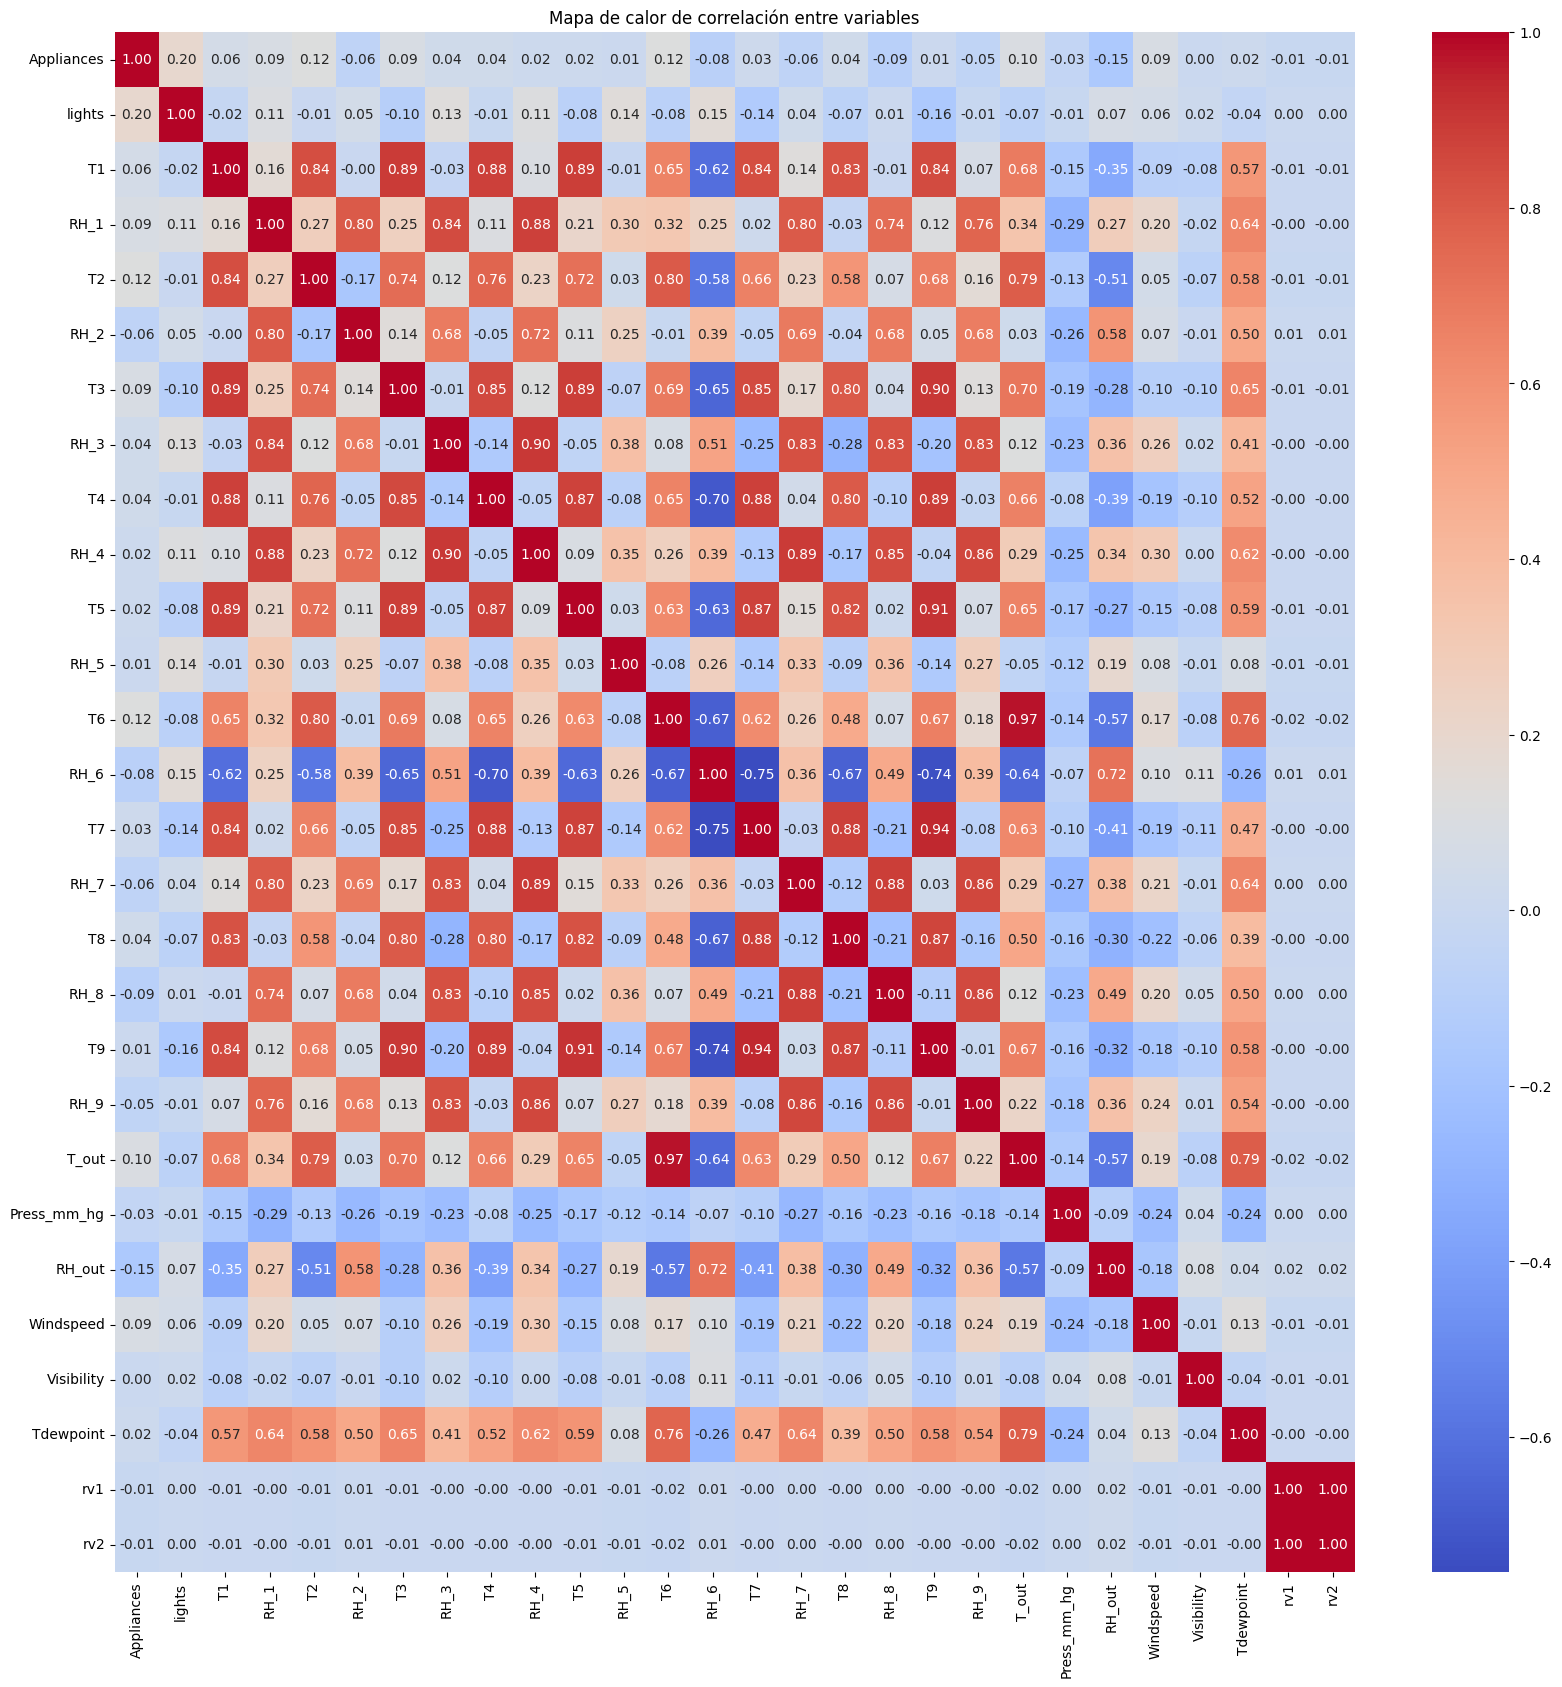

In [217]:
# Actividad: Regresión para imputación de datos
'''
1. Revisa el dataset energy data (desde la línea donde se carga la base de datos) y genera un mapa de calor utilizando la correlación entre las características con respecto a la variable objetivo (por ejemplo, appliances).
2. Selecciona las variables que consideres más relevantes para predecir la variable objetivo.
3. Cambia intervalo de datos faltantes.
4. Aplica diferentes modelos de regresión, y compara su desempeño.
5. Grafica los resultados obtenidos para cada modelo.
'''
# ==============================================================================
# 3.1 Generar un mapa de calor. Se omite la variable 'date' porque no es muy adecuada
# para los cálculos de correlación al ser periódica
# ==============================================================================

plt.figure(figsize=(20, 20))
sns.heatmap(df_original.drop(columns='date').corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de calor de correlación entre variables')
plt.show()

In [218]:
# ==============================================================================
# 3.2 Se seleccionan variables relevantes que tienen un aparente impacto en la variable
# Appliances (corr mayor a 0.1 y menor a -0.1):
# RH_out (% de humedad ambiente), lights (energía usada por bombillas, Wh),
#T2 (Temperatura de la sala, Celsius) y T6 (Temperatura fuera del edificio, Celsius)
# ==============================================================================

df = df_original[['RH_out', 'lights','T2','T6', 'Appliances']].copy()

# ==============================================================================
# 3.3 Se cambia el intervalor de datos faltantes
# ==============================================================================

df.loc[100:200, 'Appliances'] = None

In [219]:
# ==============================================================================
# 3.4 Aplicar diferentes modelos de regresión
# ==============================================================================

# Separar filas con y sin datos faltantes
df_train = df.dropna()
df_missing = df[df['Appliances'].isna()]

# Se definen los valores de prueba como los valores de Appliances antes de la
# imputación
y_test = df_original.loc[100:200, 'Appliances']

# Entrenar modelo para imputar consumo
X_train = df_train[['RH_out', 'lights','T2','T6']]
y_train = df_train['Appliances']

modelos = {
    "Lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "DecisionTree": DecisionTreeRegressor(max_depth=5, random_state=42)
}

metricas = {}
for nombre, modelo in modelos.items():

      modelo.fit(X_train, y_train)
      # Imputar valores faltantes
      X_missing = df_missing[['RH_out', 'lights','T2','T6']]
      y_pred = modelo.predict(X_missing)
      metricas[nombre] = evaluar_modelo(y_test, y_pred, nombre)


Modelo: Lineal
MAE=60.243 | MSE=8780.086 | R2=0.080

Modelo: Ridge
MAE=60.243 | MSE=8780.086 | R2=0.080

Modelo: Lasso
MAE=60.265 | MSE=8779.963 | R2=0.080

Modelo: DecisionTree
MAE=56.789 | MSE=8968.483 | R2=0.060



Se puede observar que los modelos tienen valores muy altos para las funciones de pérdida y un coeficiente R2 demasiado bajo, lo que indica que los modelos no predicen adecuadamente el valor de la variable objetivo.

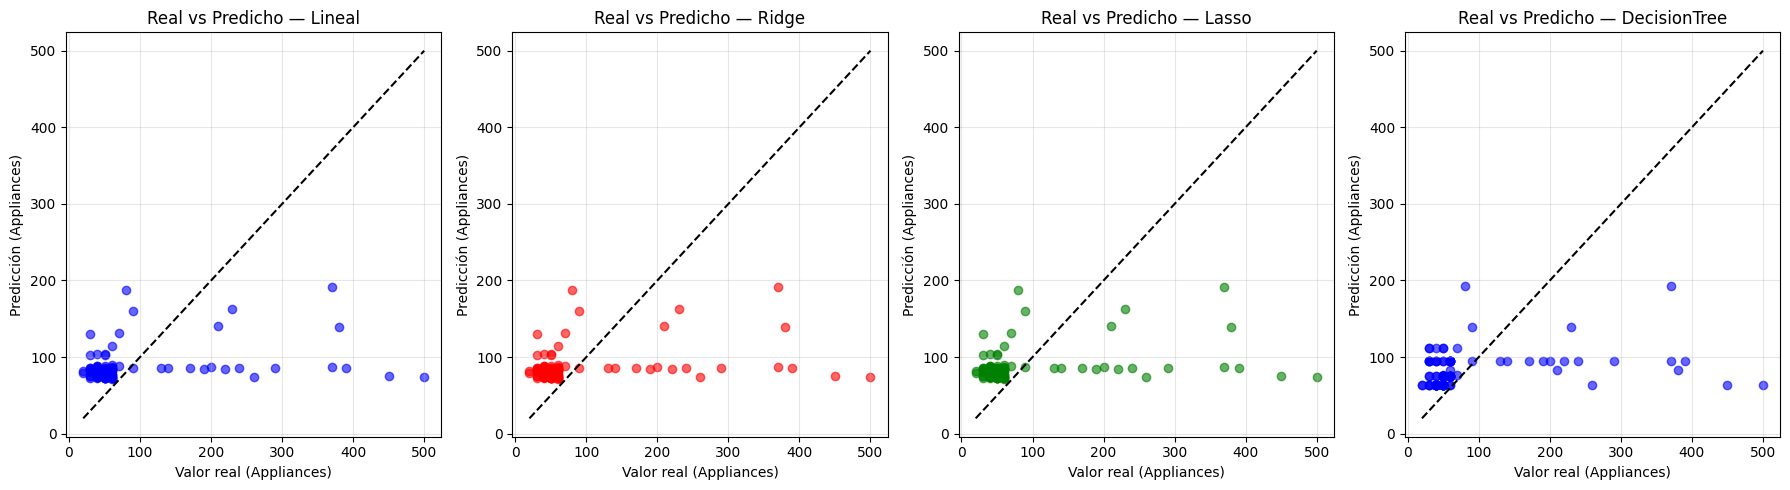

In [220]:
# ==============================================================================
# 3.5 Se grafican los datos para cada modelo
# ==============================================================================

colors = ['b','r', 'g', 'b']
model_names = list(modelos.keys())
fig, axs = plt.subplots(1, 4, figsize=(18, 5))
for i, nombre in enumerate(model_names):
    modelo = modelos[nombre]
    modelo.fit(X_train, y_train) # Fit the model before predicting
    y_pred = modelo.predict(X_missing)
    axs[i].scatter(y_test, y_pred, alpha=0.6, color=colors[i])
    axs[i].set_xlabel("Valor real (Appliances)")
    axs[i].set_ylabel("Predicción (Appliances)")
    axs[i].set_title(f"Real vs Predicho — {nombre}")
    minv, maxv = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    axs[i].plot([minv, maxv], [minv, maxv], 'k--')
    axs[i].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Como se observa en las gráficas, el ajuste es extremadamente bajo para los diferentes modelos. Hay una gran dispersión respecto al ajuste ideal y una muy baja relación entre el valor real y la predicción para la variable Appliances.

## 4. Ejercicio: Regresión para forecasting

En este ejercicio aprenderás a usar regresión para realizar pronósticos (forecasting) en series temporales reales. Usaremos datos de temperatura diaria de Melbourne y te dejaremos un espacio para que experimentes con diferentes configuraciones y modelos.

**Ejemplo:** Predicción de la temperatura mínima diaria en Melbourne usando la temperatura del día anterior (lag 1).

In [221]:
# Ejemplo: Forecasting con regresión usando datos reales de temperatura de Melbourne
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor

# Cargar datos de temperatura diaria de Melbourne
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
df = pd.read_csv(url)

# Crear variable de lag (temperatura del día anterior)
df['Temp_lag1'] = df['Temp'].shift(1)

# Eliminar la primera fila (lag vacío)
df = df.dropna()

# Entrenar modelo para predecir la temperatura usando el lag
X = df[['Temp_lag1']]
y = df['Temp']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Predecir la temperatura del día siguiente
y_pred = modelo.predict(X_test)

evaluar_modelo(y_test, y_pred, 'LinearRegression')

# print(df[['Date', 'Temp', 'Temp_lag1', 'Prediccion_lag1']].head())

Modelo: LinearRegression
MAE=1.954 | MSE=6.327 | R2=0.620



{'MAE': 1.9538349798471961, 'MSE': 6.327393262725934, 'R2': 0.6204830666064225}

Ahora es tu turno...

1. Cambia el valor de lag (por ejemplo, prueba lag de 7 o 15 días) y observa cómo cambia la predicción.
2. Prueba diferentes modelos de regresión (por ejemplo, DecisionTreeRegressor, Ridge, Lasso) y compara su desempeño.
3. Realiza una gráfica comparando las predicciones con los valores reales.
4. Calcula métricas de desempeño (MAE, RMSE, R2) para cada modelo y lag.
5. Escribe una breve conclusión sobre qué configuración y modelo predice mejor la temperatura.

In [222]:
# Actividad: Forecasting con regresión

'''
1. Cambia el valor de lag (por ejemplo, prueba lag de 7 o 15 días) y observa cómo cambia la predicción.
2. Prueba diferentes modelos de regresión (por ejemplo, DecisionTreeRegressor, Ridge, Lasso) y compara su desempeño.
3. Realiza una gráfica comparando las predicciones con los valores reales.
4. Calcula métricas de desempeño (MAE, RMSE, R2) para cada modelo y lag.
5. Escribe una breve conclusión sobre qué configuración y modelo predice mejor la temperatura.
'''
# ==============================================================================
# 4.1 Se cambia el valor de lag para la serie temporal
# ==============================================================================

#Se define nuevamente el dataframe para que no esté alterado
df = pd.read_csv(url)

lags = {
    'Temp_lag1': 1,
    'Temp_lag7': 7,
    'Temp_lag15': 15
}

# ==============================================================================
# 4.1 Se cambia el valor de lag para la serie temporal
# ==============================================================================

modelos = {
    "Lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "DecisionTree": DecisionTreeRegressor(max_depth=5, random_state=42)
}

metricas = {}
for lag, valor in lags.items():
  df[lag] = df['Temp'].shift(valor)

  # Eliminar las filas del lag vacías
  df = df.dropna()

  X = df[[lag]]
  y = df['Temp']

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
  for nombre, modelo in modelos.items():
      nombre = nombre+'_lag_'+str(valor)
      modelo.fit(X_train, y_train)
      y_pred = modelo.predict(X_test)
      df[f'Prediccion_{lag}'] = modelo.predict(X)
      metricas[nombre] = evaluar_modelo(y_test, y_pred, nombre)

#df.head(30)

Modelo: Lineal_lag_1
MAE=1.954 | MSE=6.327 | R2=0.620

Modelo: Ridge_lag_1
MAE=1.954 | MSE=6.327 | R2=0.620

Modelo: DecisionTree_lag_1
MAE=1.973 | MSE=6.298 | R2=0.622

Modelo: Lineal_lag_7
MAE=2.664 | MSE=11.393 | R2=0.351

Modelo: Ridge_lag_7
MAE=2.664 | MSE=11.393 | R2=0.351

Modelo: DecisionTree_lag_7
MAE=2.654 | MSE=11.578 | R2=0.340

Modelo: Lineal_lag_15
MAE=2.656 | MSE=11.624 | R2=0.292

Modelo: Ridge_lag_15
MAE=2.656 | MSE=11.624 | R2=0.292

Modelo: DecisionTree_lag_15
MAE=2.631 | MSE=11.451 | R2=0.302



Del resultado de las métricas de las funciones de pérdida se observa que a medida que el lag es mayor, menos ajustado es el modelo y menor capacidad tendría de predecir los valores de la variable dependiente.

En los tres modelos analizados, parece que el Árbol de decisiones es el que mejor se ajustaría para este tipo de problemas.

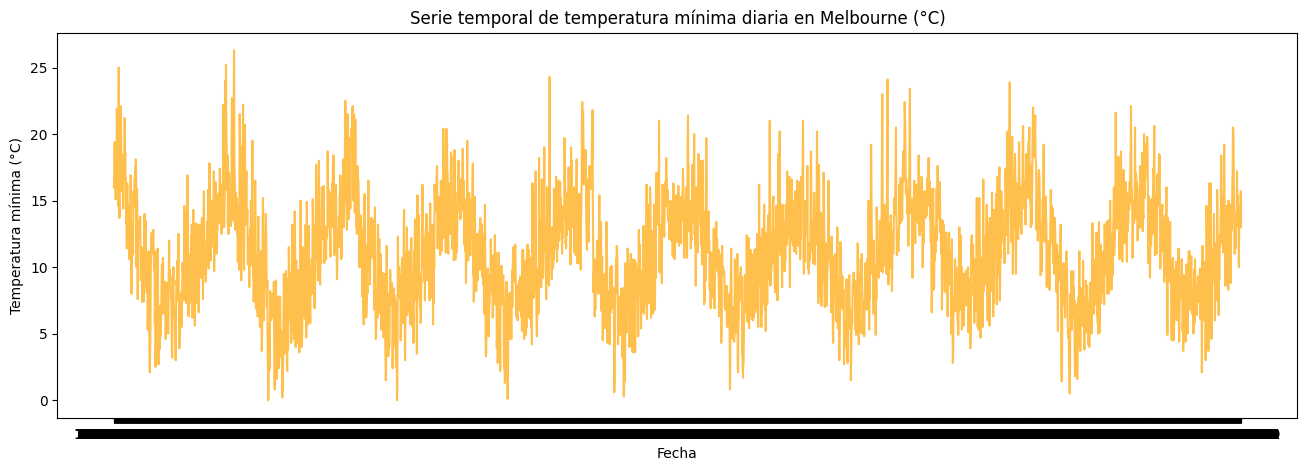

In [223]:
# ==============================================================================
# 4.3 Se realizan gráficas de las series temporales
# ==============================================================================

# Visualización de la serie
plt.figure(figsize=(16,5))
plt.plot(df['Date'], df['Temp'], color='orange', alpha=0.7)
plt.title('Serie temporal de temperatura mínima diaria en Melbourne (°C)')
plt.xlabel('Fecha')
plt.ylabel('Temperatura mínima (°C)')
plt.show()



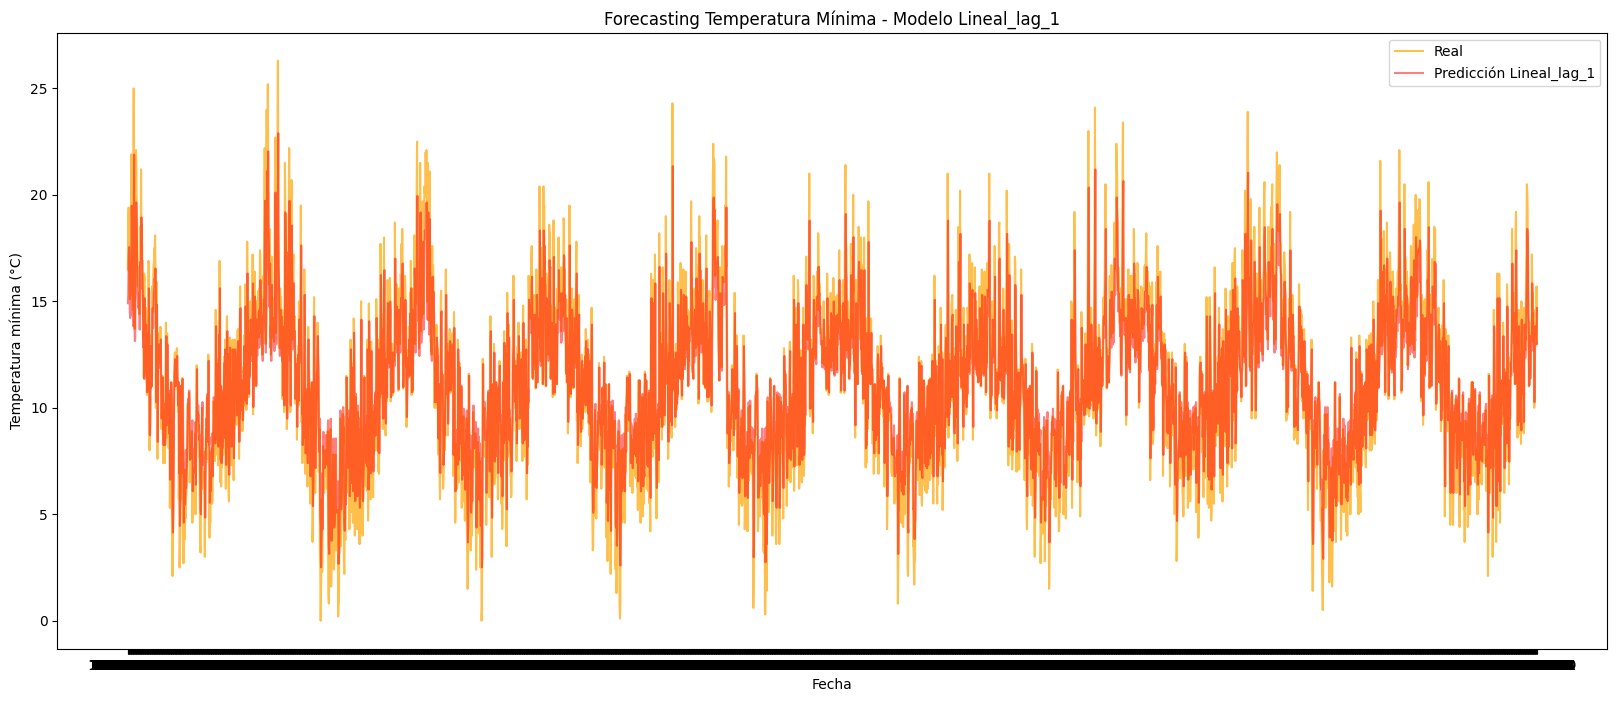

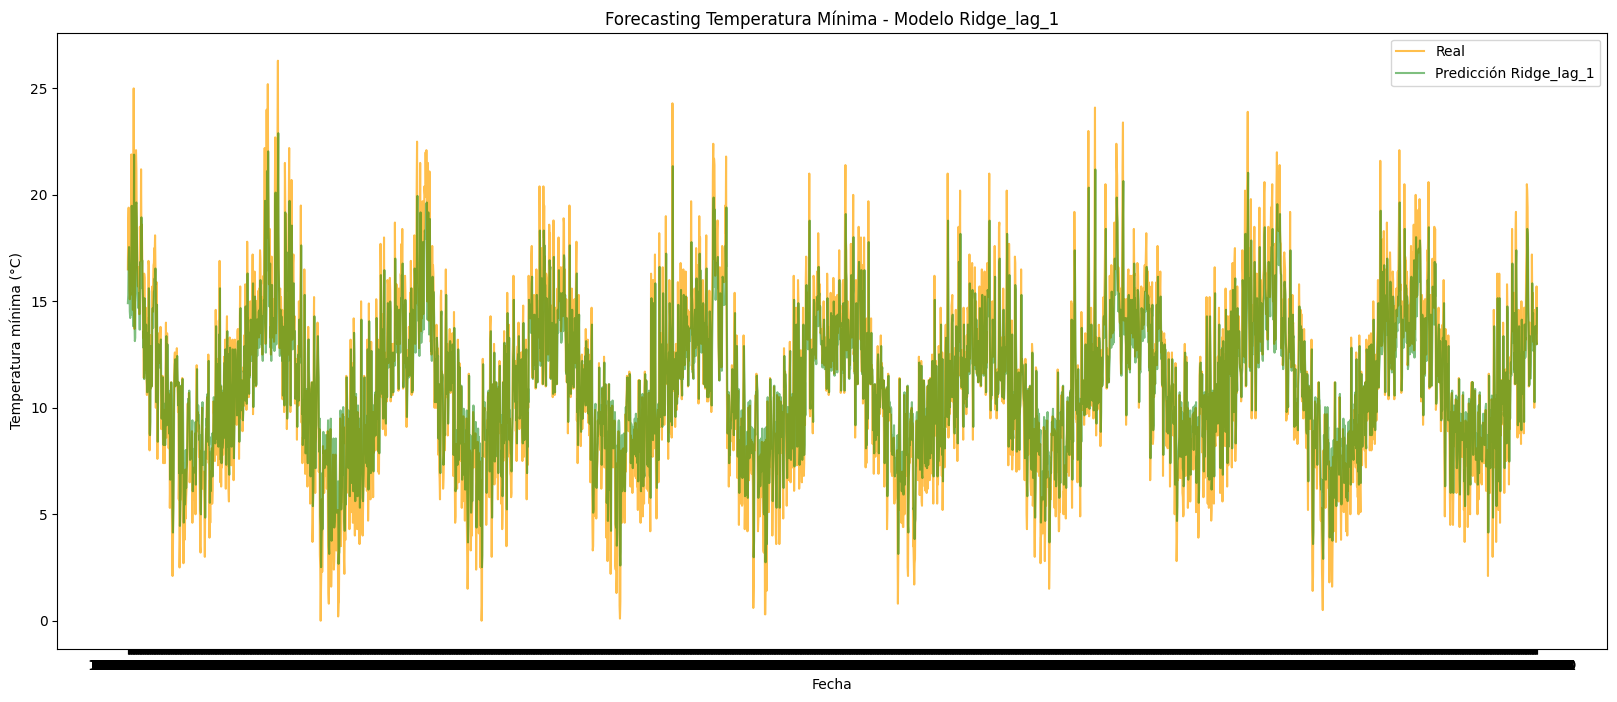

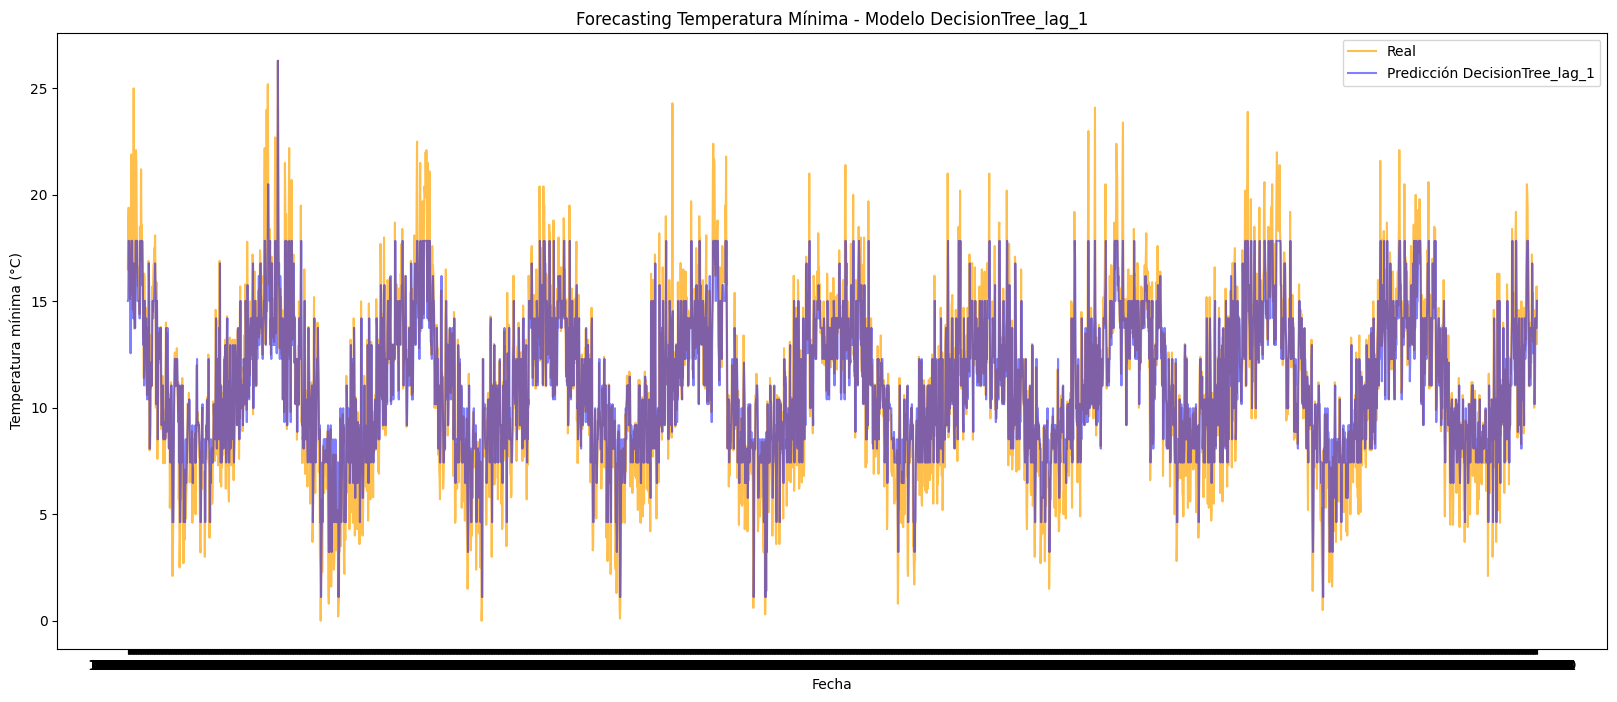

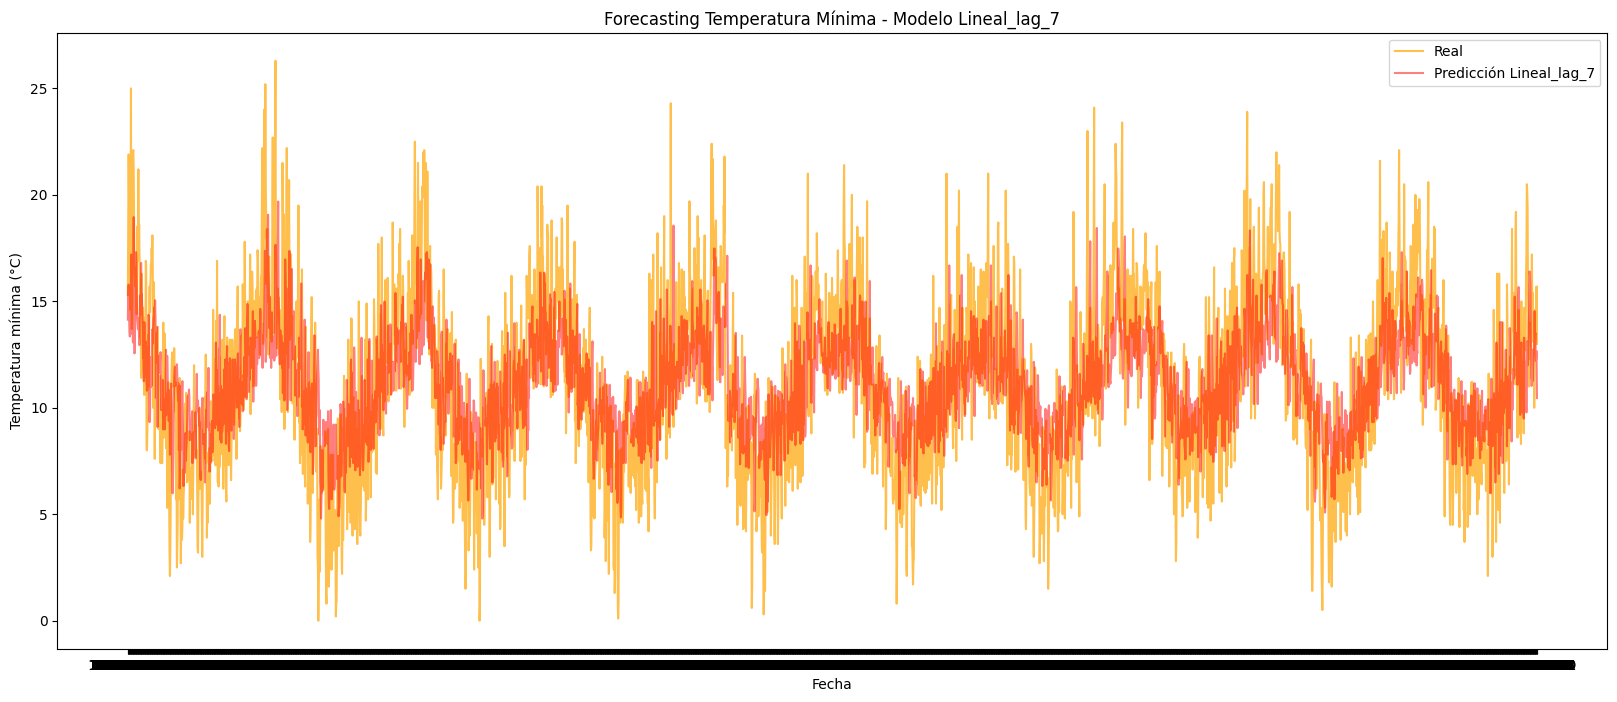

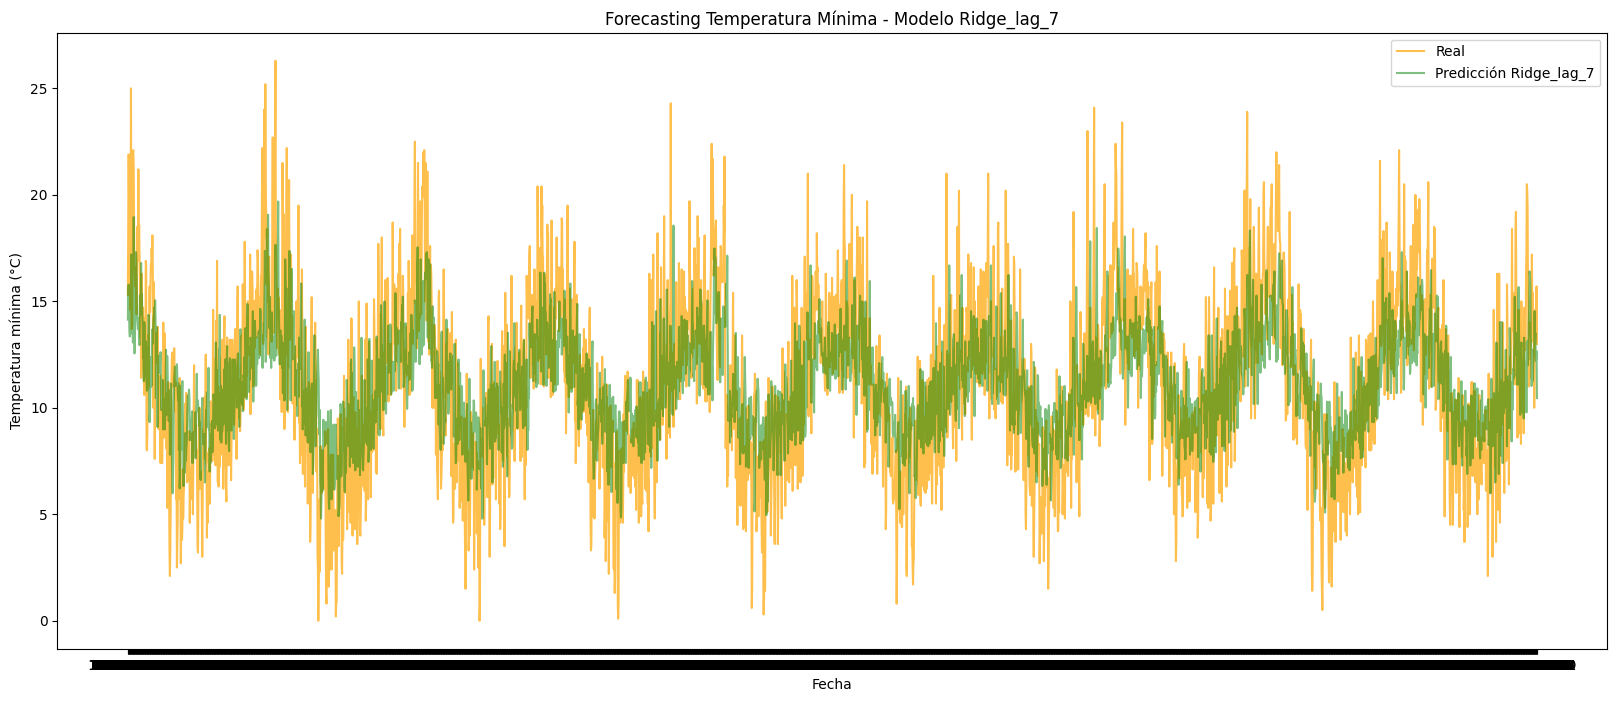

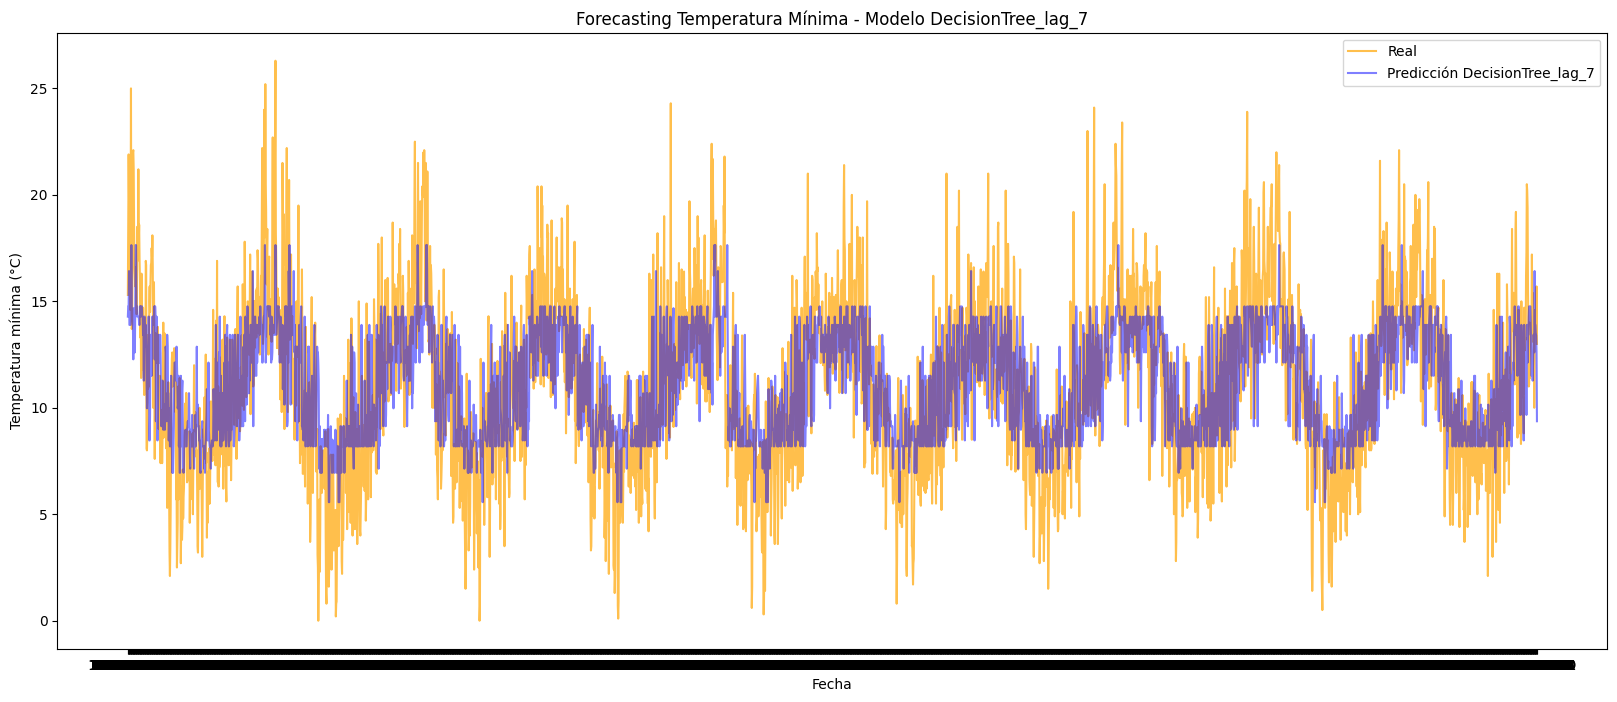

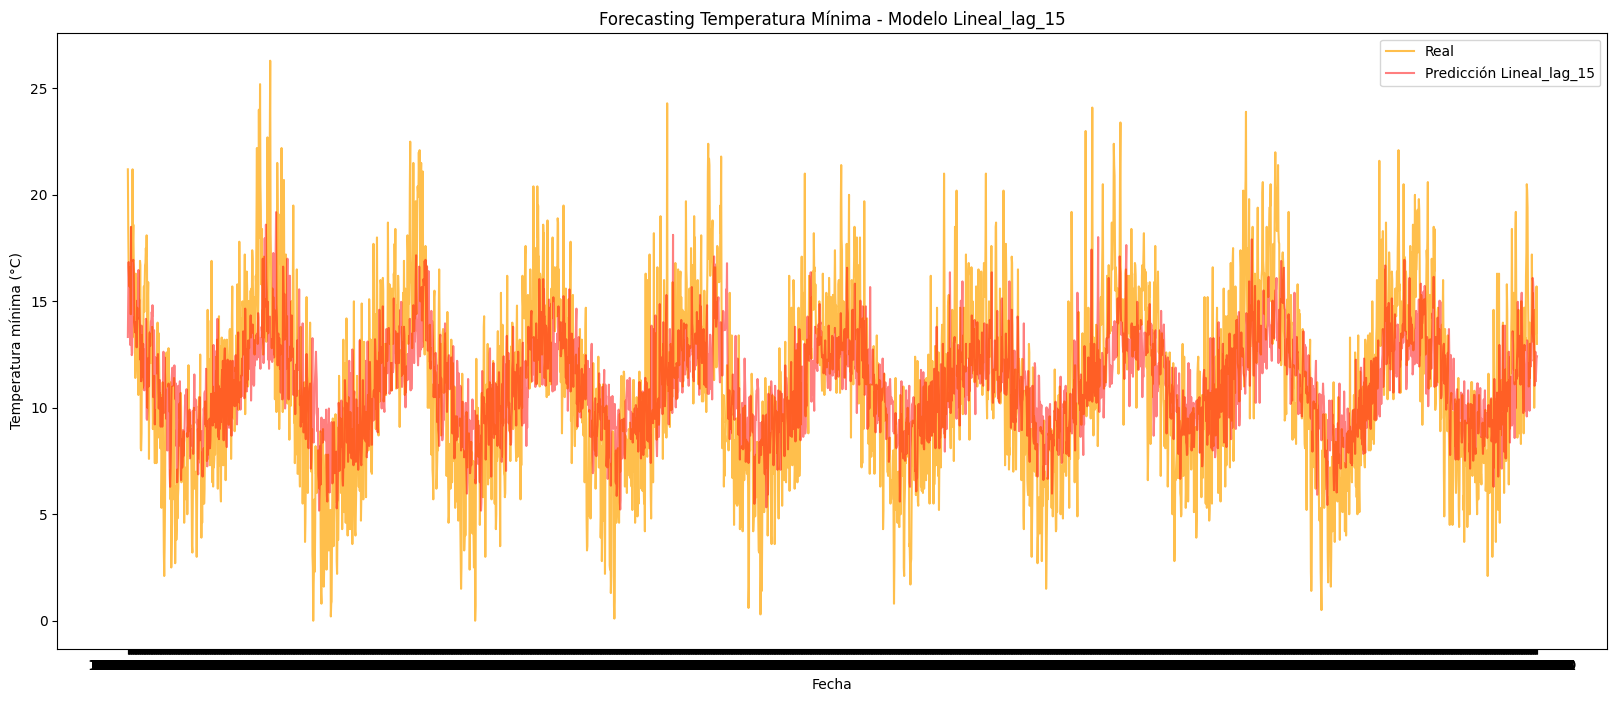

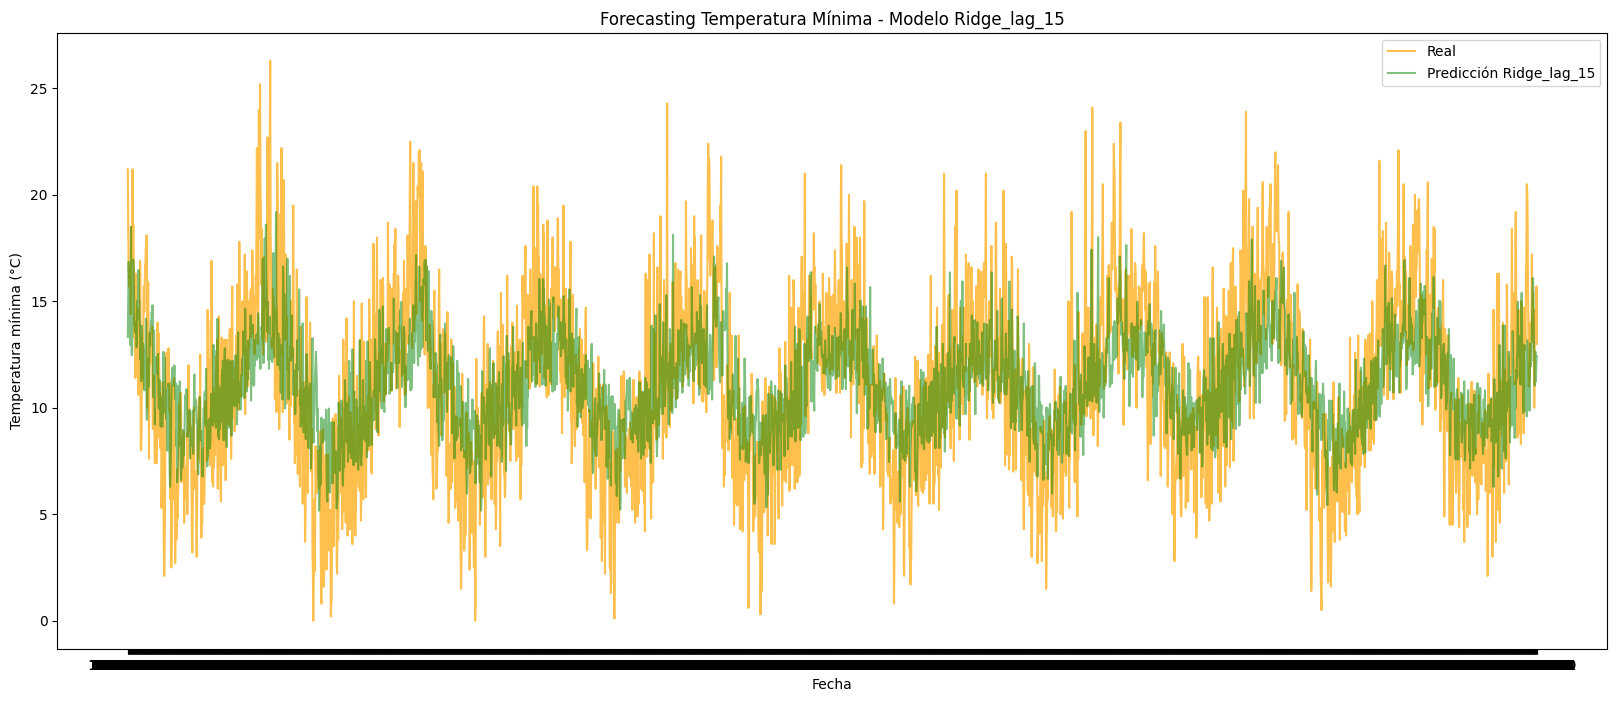

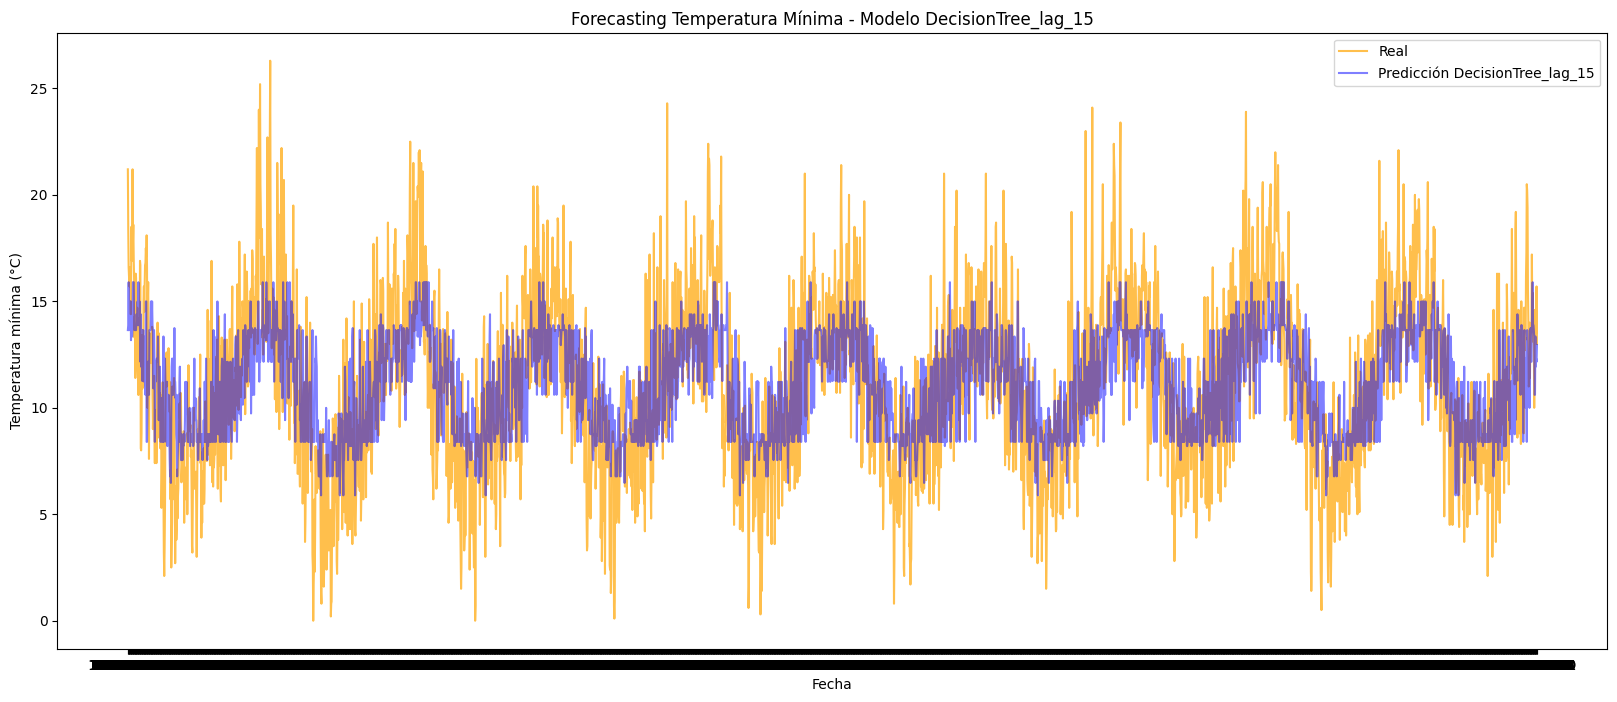

In [224]:
# Visualización de la serie comparada con los modelos
metricas = {}
colors = ['r', 'g', 'b']
for lag, valor in lags.items():
  i=0
  df[lag] = df['Temp'].shift(valor)

  # Eliminar las filas del lag vacías
  df = df.dropna()

  X = df[[lag]]
  y = df['Temp']

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

  for nombre, modelo in modelos.items():
    color_serie = colors[i]
    i+=1
    nombre = nombre+'_lag_'+str(valor)
    # Se entrena el modelo nuevamente usando la partición anterior y el mismo random state
    modelo.fit(X_train, y_train)

    # Se corre el modelo para predecir el total de los datos
    y_total_pred_modelo = modelo.predict(X)

    plt.figure(figsize=(20,8))
    plt.plot(df['Date'], df['Temp'], alpha=0.7, label='Real', color='orange')
    plt.plot(df['Date'], y_total_pred_modelo,alpha=0.5, label=f'Predicción {nombre}', color=color_serie)
    plt.title(f'Forecasting Temperatura Mínima - Modelo {nombre}')
    plt.xlabel('Fecha')
    plt.ylabel('Temperatura mínima (°C)')
    plt.legend()
    plt.show()


Las gráficas permiten confirmar lo que se mostraba en las métricas de las funciones de pérdida, que a medida que aumenta el lag, la predicción de la variable dependientes es más incorrecta para los diferentes modelos. Sin embargo, se aprecia que los modelos pueden predecir la periodicidad en el comportamiento de la variable, pero no pueden predecir adecuadamente los valores superiores e inferiores de la varaible objetivo.